In [139]:
import numpy as np
import torch
import torch.nn as nn
from torch.optim import Adam
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns


In [140]:
SEED = 42
DEVICE = 'cpu'

np.random.seed(SEED)
torch.manual_seed(SEED)

sns.set_style("darkgrid")

In [141]:
mixture_prob = np.array([0.55, 0.45], dtype=float)
mixture_mus = np.array([-0.85, 1.5], dtype=float)
mixture_sigmas = np.array([0.65, 0.25], dtype=float)

def mixture_sample(size: int) -> np.ndarray:
    rand_idx = np.random.choice(range(len(mixture_prob)), size=size, p=mixture_prob)
    means = mixture_mus[rand_idx]
    stds = mixture_sigmas[rand_idx]
    return np.random.normal(loc=means, scale=stds)

def interpolate_linear(x_0, x_1, t):
    x_t = ((1 - t) * x_0) + (t * x_1)
    return x_t

def get_target_velocity(x_0, x_1):
    return x_1 - x_0

In [142]:
class FlowMatchingModel(nn.Module):
    def __init__(self, data_dim: int = 1, hidden_dim: int = 64) -> None:
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(data_dim + 1, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(), 
            nn.Linear(hidden_dim, data_dim)
        )

    def forward(self, t, x_t):
        tx = torch.cat([t, x_t], dim=-1)
        return self.net(tx)

In [143]:
def compute_loss(fmm: FlowMatchingModel, x_0, x_1, t):
    x_t = interpolate_linear(x_0, x_1, t)
    v_target = get_target_velocity(x_0, x_1)
    v_pred = fmm(t, x_t)

    loss = ((v_pred - v_target)**2).mean()
    
    return loss

In [144]:
n = 10_000
lr = 1e-3
batch_size = 256

100%|██████████| 10000/10000 [00:10<00:00, 939.71it/s, Loss=2.21]


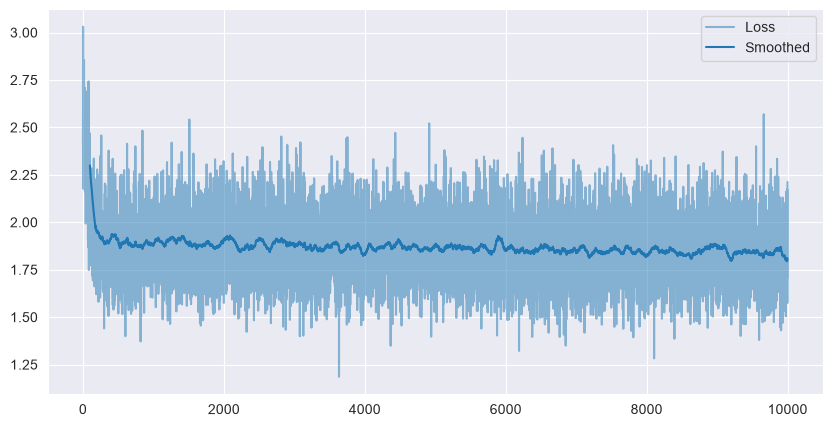

In [145]:
fm = FlowMatchingModel().to(DEVICE).train()
optimizer = Adam(fm.parameters(), lr)

losses = []

with tqdm(range(n)) as pb:
    for i in pb:
        x_1 = torch.from_numpy(mixture_sample(batch_size)).to(dtype=torch.float32, device=DEVICE).unsqueeze(-1)
        x_0 = torch.randn_like(x_1)
        t = torch.rand(x_1.shape[0], device=DEVICE).unsqueeze(-1)

        loss = compute_loss(fm, x_0, x_1, t)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        losses.append(loss.item())
        pb.set_postfix({'Loss': f'{loss.item():.2f}'})

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(losses, label='Loss', color="tab:blue", alpha=0.5)

ws = min(100, n)
smoothed = np.convolve(losses, np.ones(ws) / ws, mode="valid")
ax.plot(np.arange(ws-1, len(losses)), smoothed, label="Smoothed", color="tab:blue")

plt.legend()
plt.show()

In [146]:
n_flow_steps = 1_000
img_hist_size = 200
x_min, x_max = -2.2, 2.2

flow_field_img_bins = np.zeros((n_flow_steps + 1, img_hist_size))
flow_field_img_x_bin_edges = np.linspace(x_min, x_max, img_hist_size + 1)
flow_field_img_x_bin_centers = (
    torch.from_numpy((flow_field_img_x_bin_edges[:-1] + flow_field_img_x_bin_edges[1:]) / 2)
    .float()
    .to(DEVICE)
    .unsqueeze(-1)
)

with torch.inference_mode():
    fm.eval()
    for i, t in enumerate(torch.linspace(0, 1, n_flow_steps + 1)):
        t = t.expand_as(flow_field_img_x_bin_centers).to(DEVICE)
        flow_field_img_bins[i] = (
            fm(t=t, x_t=flow_field_img_x_bin_centers).cpu().numpy().squeeze()
        )

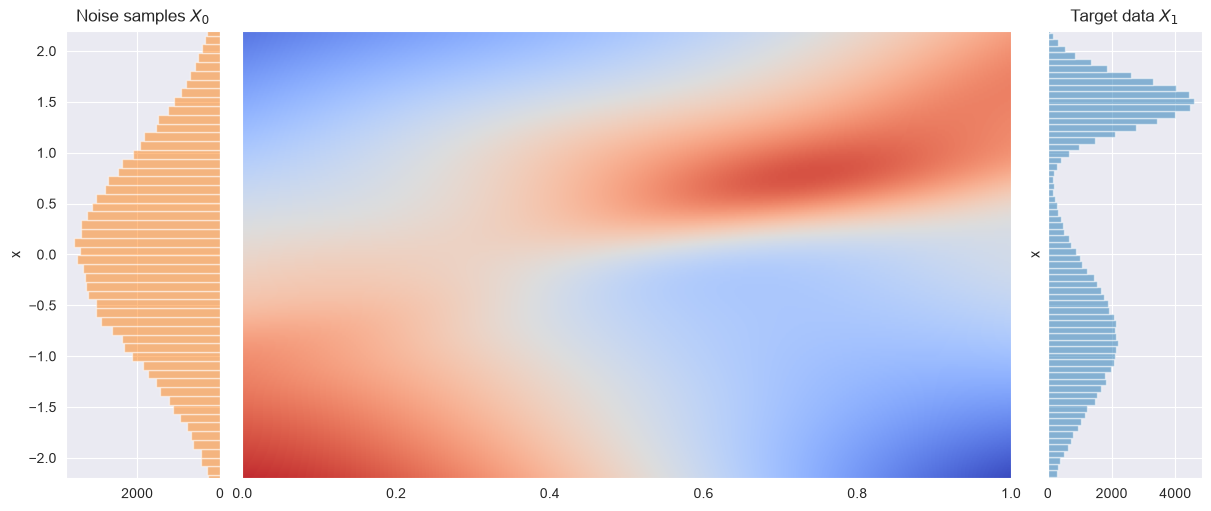

In [147]:
data_size: int = 100_000
data_x_0 = np.random.randn(data_size)
data_x_1 = mixture_sample(size=data_size)

def plot_distribution(ax, data, title, color, inverted=False):
    ax.set_title(title)
    ax.hist(
        data.flatten(),
        bins=100,
        alpha=0.5,
        color=color,
        orientation="horizontal",
    )
    if inverted:
        ax.invert_xaxis()
    ax.set_ylabel("x")

def plot_vector_field(ax, field, x_min, x_max):
    max_abs_flow_field = np.nanmax(np.abs(field))
    color_norm = matplotlib.colors.TwoSlopeNorm(vmin=-max_abs_flow_field, vcenter=0.0, vmax=max_abs_flow_field)
    im = ax.imshow(
        field.T,
        aspect="auto",
        origin="lower",
        extent=[0, 1, x_min, x_max],
        cmap="coolwarm",
        norm=color_norm,
    )
    ax.set_ylim(x_min, x_max)
    ax.grid(False)


def plot_flow_matching(data_x_0, data_x_1, field, x_min, x_max):
    fig, (ax1, ax2, ax3) = plt.subplots(
        1,
        3,
        figsize=(12, 5),
        gridspec_kw={"width_ratios": [1, 5, 1]},
        sharey=True,
        dpi=100,
        constrained_layout=True,
    )

    plot_distribution(ax1, data_x_0, r"Noise samples $X_0$", "tab:orange", True)
    plot_vector_field(ax2, field, x_min, x_max)
    plot_distribution(ax3, data_x_1, r"Target data $X_1$", "tab:blue")

plot_flow_matching(
    data_x_0,
    data_x_1,
    flow_field_img_bins,
    x_min,
    x_max
)
